#### Nama: Rifky Hermawan
#### NIM: 053102749

In [14]:
# Customer Personality Analysis - Unsupervised Learning Tugas 3


import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

# Step 1: Load dataset

In [2]:
df = pd.read_csv('cpa.csv', sep='\t')
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


#Step2: lakukan Eksplorasi awal

In [3]:
display(df.info())
display(df.isnull().sum())
display(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   i

None

,0
ID,0
Year_Birth,0
Education,0
Marital_Status,0
Income,24
Kidhome,0
Teenhome,0
Dt_Customer,0
Recency,0
MntWines,0


,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
count,2240.000000,2240.000000,2216.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,...,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.0,2240.0,2240.000000
mean,5592.159821,1968.805804,52247.251354,0.444196,0.506250,49.109375,303.935714,26.302232,166.950000,37.525446,...,5.316518,0.072768,0.074554,0.072768,0.064286,0.013393,0.009375,3.0,11.0,0.149107
std,3246.662198,11.984069,25173.076661,0.538398,0.544538,28.962453,336.597393,39.773434,225.715373,54.628979,...,2.426645,0.259813,0.262728,0.259813,0.245316,0.114976,0.096391,0.0,0.0,0.356274
min,0.000000,1893.000000,1730.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
25%,2828.250000,1959.000000,35303.000000,0.000000,0.000000,24.000000,23.750000,1.000000,16.000000,3.000000,...,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
50%,5458.500000,1970.000000,51381.500000,0.000000,0.000000,49.000000,173.500000,8.000000,67.000000,12.000000,...,6.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
75%,8427.750000,1977.000000,68522.000000,1.000000,1.000000,74.000000,504.250000,33.000000,232.000000,50.000000,...,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
max,11191.000000,1996.000000,666666.000000,2.000000,2.000000,99.000000,1493.000000,199.000000,1725.000000,259.000000,...,20.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.0,11.0,1.000000


## Feature Engineering

In [4]:
# 1. Memperbaiki Year_Birth menjadi Umur
df['Umur'] = 2014 - df['Year_Birth']

# 2. Memperbaiki Dt_Customer menjadi Lama_Berlangganan
df['Dt_Customer'] = pd.to_datetime(df['Dt_Customer'], format='%d-%m-%Y')
tanggal_terbaru = df['Dt_Customer'].max()
df['Lama_Berlangganan'] = (tanggal_terbaru - df['Dt_Customer']).dt.days

# 3. Menghapus kolom asli agar tidak ikut di-encode atau scaling
df = df.drop(columns=['Year_Birth', 'Dt_Customer'])

# Step 3: Identifikasi kolom numerik & kategori

In [5]:
num_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()

if 'ID' in num_cols:
    num_cols.remove('ID')

print("Kolom Numerik:", num_cols)
print("Kolom Kategori:", cat_cols)

Kolom Numerik: ['Income', 'Kidhome', 'Teenhome', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response', 'Umur', 'Lama_Berlangganan']
Kolom Kategori: ['Education', 'Marital_Status']


# Step 4: Imputasi missing value

In [6]:
num_imputer = SimpleImputer(strategy='median')
cat_imputer = SimpleImputer(strategy='most_frequent')

df[num_cols] = num_imputer.fit_transform(df[num_cols])
if len(cat_cols) > 0:
    df[cat_cols] = cat_imputer.fit_transform(df[cat_cols])


# Step 5: Encoding fitur kategori

In [7]:
if len(cat_cols) > 0:
    encoder = OneHotEncoder(sparse_output=False, drop='first')
    encoded_cats = encoder.fit_transform(df[cat_cols])
    encoded_cat_names = encoder.get_feature_names_out(cat_cols)
    df_cat_encoded = pd.DataFrame(encoded_cats, columns=encoded_cat_names, index=df.index)
    display(df_cat_encoded.head())
else:
    print("Tidak ada kolom kategori.")

,Education_Basic,Education_Graduation,Education_Master,Education_PhD,Marital_Status_Alone,Marital_Status_Divorced,Marital_Status_Married,Marital_Status_Single,Marital_Status_Together,Marital_Status_Widow,Marital_Status_YOLO
0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


#Gabungkan data numerik & hasil encoding

In [8]:
if len(cat_cols) > 0:
    df_processed = pd.concat([df[num_cols], df_cat_encoded], axis=1)
else:
    df_processed = df[num_cols].copy()

display(df_processed.head())

,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,...,Education_Graduation,Education_Master,Education_PhD,Marital_Status_Alone,Marital_Status_Divorced,Marital_Status_Married,Marital_Status_Single,Marital_Status_Together,Marital_Status_Widow,Marital_Status_YOLO
0,58138.0,0.0,0.0,58.0,635.0,88.0,546.0,172.0,88.0,88.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,46344.0,1.0,1.0,38.0,11.0,1.0,6.0,2.0,1.0,6.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,71613.0,0.0,0.0,26.0,426.0,49.0,127.0,111.0,21.0,42.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,26646.0,1.0,0.0,26.0,11.0,4.0,20.0,10.0,3.0,5.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,58293.0,1.0,0.0,94.0,173.0,43.0,118.0,46.0,27.0,15.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


# Step 6: Scaling data

In [9]:
scaler = StandardScaler()
df_scaled = pd.DataFrame(scaler.fit_transform(df_processed), columns=df_processed.columns)
display(df_scaled.head())

,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,...,Education_Graduation,Education_Master,Education_PhD,Marital_Status_Alone,Marital_Status_Divorced,Marital_Status_Married,Marital_Status_Single,Marital_Status_Together,Marital_Status_Widow,Marital_Status_YOLO
0,0.235696,-0.825218,-0.929894,0.307039,0.983781,1.551577,1.679702,2.462147,1.476500,0.843207,...,0.993769,-0.444816,-0.526385,-0.036621,-0.339909,-0.792406,1.914854,-0.591099,-0.188676,-0.029894
1,-0.235454,1.032559,0.906934,-0.383664,-0.870479,-0.636301,-0.713225,-0.650449,-0.631503,-0.729006,...,0.993769,-0.444816,-0.526385,-0.036621,-0.339909,-0.792406,1.914854,-0.591099,-0.188676,-0.029894
2,0.773999,-0.825218,-0.929894,-0.798086,0.362723,0.570804,-0.177032,1.345274,-0.146905,-0.038766,...,0.993769,-0.444816,-0.526385,-0.036621,-0.339909,-0.792406,-0.522233,1.691765,-0.188676,-0.029894
3,-1.022355,1.032559,-0.929894,-0.798086,-0.870479,-0.560857,-0.651187,-0.503974,-0.583043,-0.748179,...,0.993769,-0.444816,-0.526385,-0.036621,-0.339909,-0.792406,-0.522233,1.691765,-0.188676,-0.029894
4,0.241888,1.032559,-0.929894,1.550305,-0.389085,0.419916,-0.216914,0.155164,-0.001525,-0.556446,...,-1.006270,-0.444816,1.899751,-0.036621,-0.339909,1.261980,-0.522233,-0.591099,-0.188676,-0.029894



# Step 7: Tentukan jumlah cluster optimal (Elbow + Silhouette)

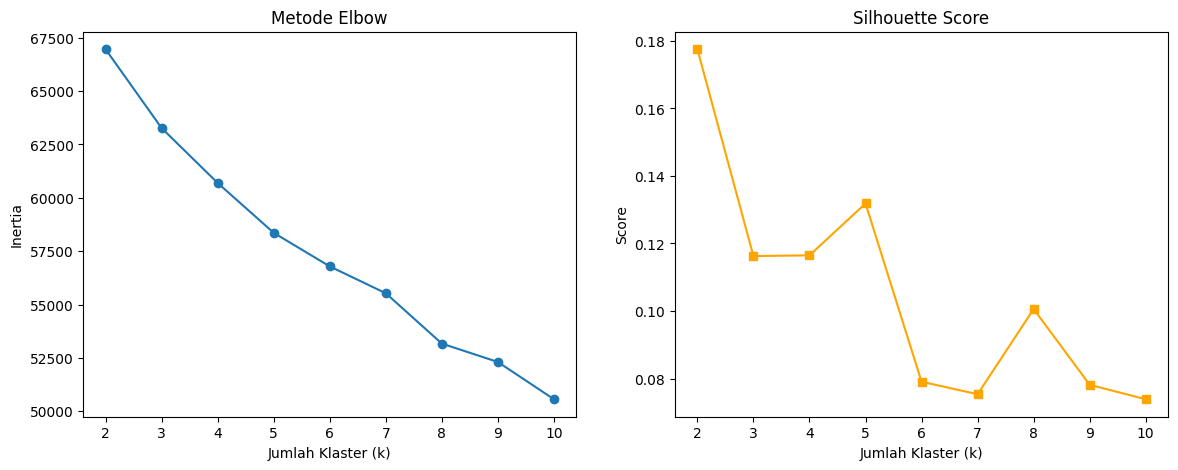

In [10]:
inertia = []
silhouette_scores = []
K = range(2, 11)

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(df_scaled)
    inertia.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(df_scaled, kmeans.labels_))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].plot(K, inertia, marker='o')
ax[0].set_title('Metode Elbow')
ax[0].set_xlabel('Jumlah Klaster (k)')
ax[0].set_ylabel('Inertia')

ax[1].plot(K, silhouette_scores, marker='s', color='orange')
ax[1].set_title('Silhouette Score')
ax[1].set_xlabel('Jumlah Klaster (k)')
ax[1].set_ylabel('Score')
plt.show()

# Step 8: Pilih k optimal dan klasterisasi

In [11]:
k_optimal = 2
kmeans_final = KMeans(n_clusters=k_optimal, random_state=42, n_init=10)
df['Cluster'] = kmeans_final.fit_predict(df_scaled)

print("Jumlah pelanggan per klaster:")
print(df['Cluster'].value_counts())

Jumlah pelanggan per klaster:
Cluster
0    1353
1     887
Name: count, dtype: int64


# Step 9: Visualisasi klaster dengan PCA 2D

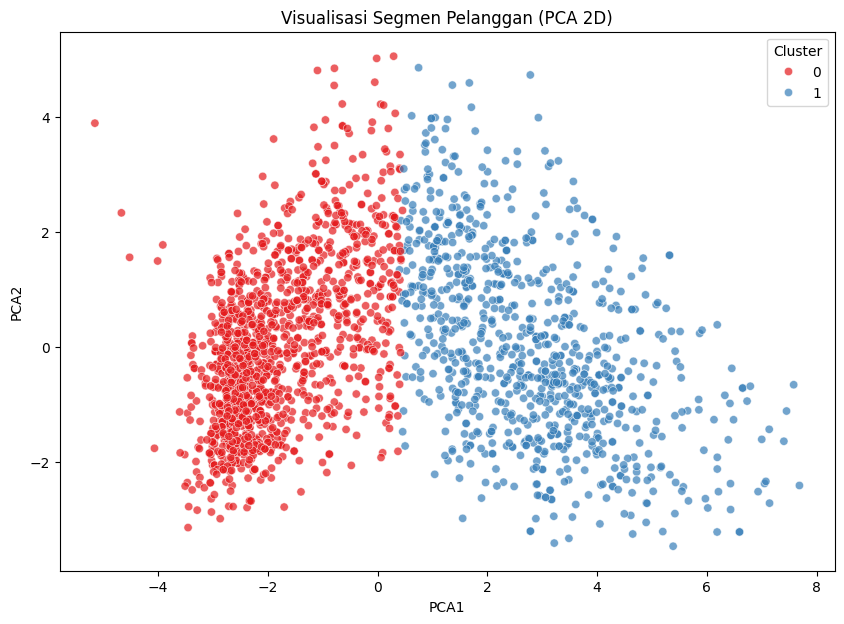

In [12]:
pca = PCA(n_components=2)
pca_components = pca.fit_transform(df_scaled)

df_pca = pd.DataFrame(data=pca_components, columns=['PCA1', 'PCA2'])
df_pca['Cluster'] = df['Cluster']

plt.figure(figsize=(10, 7))
sns.scatterplot(x='PCA1', y='PCA2', hue='Cluster', data=df_pca, palette='Set1', alpha=0.7)
plt.title('Visualisasi Segmen Pelanggan (PCA 2D)')
plt.show()

# Step 10: Profiling cluster (rata-rata fitur per cluster)

In [13]:
cluster_profile = df.groupby('Cluster')[num_cols].mean()
display(cluster_profile.T)

Cluster,0,1
Income,39204.325203,72119.067644
Kidhome,0.692535,0.065389
Teenhome,0.558758,0.426156
Recency,48.827051,49.540023
MntWines,105.441242,606.712514
MntFruits,6.631190,56.307779
MntMeatProducts,37.811530,363.933484
MntFishProducts,9.792313,79.828636
MntSweetProducts,6.830007,57.925592
MntGoldProds,22.747967,76.472379


# Simpulkan Analisa dari hasil

Berdasarkan hasil rata-rata tiap klaster di atas, kita dapat simpulkan bahwa pelanggan terbagi menjadi dua tipe yang lumayan bertolak belakang. Cluster 1 itu ibarat pelanggan kelas atas yang memiliki banyak uang. Rata-rata pendapatan mereka tinggi sekitar 70 ribuan dan kebanyakan dari mereka sudah tidak memiliki tanggungan anak kecil di rumah. Maka dari itu, pengeluaran mereka buat membeli barang-barang tersier seperti wine, daging, sampai perhiasan emas jauh lebih besar. Mereka juga hobi belanja melalui platform apapun, baik itu lewat web, katalog, maupun datang langsung ke toko. Cluster 1 ini juga termasuk yang paling gampang dirayu dengan campaign atau promo.

Sebaliknya, Cluster 0 itu tipe pelanggan yang lebih hemat karena rata-rata pendapatan mereka hanya setengahnya dari Cluster 0 yaitu sekitar 37 ribuan dan rata-rata memiliki anak kecil di rumah. Uniknya, pelanggan di Cluster 0 ini sering sekali membuka website yang terbukti dari angka kunjungan web yang tinggi, tetapi jarang yang serius berbelanja atau hanya window shopping saja. Kalaupun mereka memutuskan untuk membeli barang, mereka lebih sering mengandalkan barang yang lagi diskon saja.

Jadi pada intinya, Cluster 1 adalah target pasar utama yang loyal dan mudah belanja, sedangkan Cluster 0 itu pelanggan yang butuh digoda menggunakan diskon yang besar agar bersedia membeli barang.
